<a href="https://colab.research.google.com/github/rabiakrann/Ileri-Oruntu-Tanima/blob/main/hafta%203.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.datasets import load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold

In [2]:
SEED=42
k_values=list(range(2,51))
k_31=5
blue, orange="#2a78d6", "#eb6834"

In [3]:
def split_one_class(X, y, seed=SEED):
    normal, anomaly = X[y==0], X[y==1]
    X_train, rest_normal = train_test_split(normal, train_size=0.6, random_state=seed)
    X_rest=np.vstack([rest_normal, anomaly])
    y_rest=np.array([0] * len(rest_normal)+[1]*len(anomaly))
    X_val, X_test, y_val, y_test = train_test_split(
        X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=seed)
    return X_train, X_val, y_val, X_test, y_test

In [4]:
def standardize(X_train, *others):
  mu, sd=X_train.mean(axis=0), X_train.std(axis=0)
  sd[sd==0]=1.0
  return [(Z-mu)/sd for Z in (X_train,)+others]

In [5]:
def knn_score(points, train, k, exclude_self=False):
    scores=[]
    for i, p in enumerate(points):
        d=np.sqrt(((train - p)**2).sum(axis=1))
        if exclude_self:
            d[i]=np.inf
        scores.append(np.sort(d)[:k].mean())
    return np.array(scores)

In [6]:
def confusion(y_true, y_pred):
    tn=fp=fn=tp=0
    for t, p in zip(y_true, y_pred):
        if t==0 and p==0:
            tn+=1
        elif t==0 and p==1:
            fp+=1
        elif t==1 and p==0:
            fn+=1
        else:
            tp+=1
    return tn, fp, fn, tp

In [7]:
def f1_score(tn, fp, fn, tp):
    precision=tp/(tp+fp) if tp+fp else 0
    recall=tp/(tp+fn) if tp+fn else 0
    return 2*precision * recall / (precision + recall) if precision+recall else 0

In [8]:
def balanced_accuracy(tn, fp, fn,tp):
  tpr=tp/(tp+fn) if tp+fn else 0
  tnr=tn/(tn+fp) if tn+fp else 0
  return (tpr+tnr)/2

In [9]:
def predict(scores, th):
  return (scores>th).astype(int)

In [10]:
def roc_curve(y_true, scores):
  P=sum(1 for t in y_true if t==1)
  N=len(y_true)-P
  order=np.argsort(-scores)
  s_sorted, y_sorted=scores[order], y_true[order]
  tpr, fpr=[0.0], [0.0]
  tp=fp=0
  for i in range(len(s_sorted)):
    if y_sorted[i]==1:
      tp+=1
    else:
      fp+=1
    if i==len(s_sorted)-1 or s_sorted[i+1] != s_sorted[i]:
      tpr.append(tp/P)
      fpr.append(fp/N)
  return np.array(fpr), np.array(tpr)

In [11]:
def auc(fpr, tpr):
  area=0.0
  for i in range(1,len(fpr)):
    area+=(fpr[i]-fpr[i-1])*(tpr[i]+tpr[i-1])/2
  return area

In [12]:
def standardization_check(X, names, limit=0.5):
  std, var=X.std(axis=0), X.var(axis=0)
  share=var/var.sum()
  eff=1/(share**2).sum()
  nz=std>0
  skew=np.zeros(X.shape[1])
  skew[nz]=((X[:, nz] - X[:, nz].mean(axis=0))**3).mean(axis=0)/std[nz]**3
  print(f"etkili özellik sayısı: {eff:.2f} of {X.shape[1]}")
  for j in np.argsort(-share)[:3]:
    print(f"  {names[j][:22]:<22} share = {share[j]:6.1%}   skewness = {skew[j]:6.2f}")
    print("  -> Uzaklığa tek bir özellik hâkim: standardizasyon GEREKLİDİR" if share.max() > limit
          else "  -> Uzaklığa tek bir özellik hakim değil.")

In [13]:
def zscore_check(X, names, T=4):
  means, stds = X.mean(axis=0), X.std(axis=0)
  z_mean = (means - means.mean()) / means.std()
  z_std = (stds - stds.mean()) / stds.std()
  if X.shape[1] <= 30:
    print(f"z(mean) : {np.round(z_mean, 2)}")
    print(f"z(std)  : {np.round(z_std, 2)}")
  out = [j for j in range(X.shape[1]) if abs(z_mean[j]) > T or abs(z_std[j]) > T]
  for j in out:
    print(f"  {names[j]}: z(mean) = {z_mean[j]:.2f}, z(std) = {z_std[j]:.2f}")
  print(f"  max |z(mean)| = {np.abs(z_mean).max():.2f}, max |z(std)| = {np.abs(z_std).max():.2f}, T = {T}")
  print("  -> standardization NEEDED" if out else "  -> no feature with |z| > T")

In [14]:
def knn_classify(X_test, X_train, y_train, k):
    pred=[]
    for p in X_test:
        d=np.sqrt(((X_train - p) **2).sum(axis=1))
        votes=np.bincount(y_train[np.argsort(d)[:k]])
        pred.append(np.argmax(votes))
    return np.array(pred)

In [15]:
data = loadmat("/content/drive/MyDrive/Colab Notebooks/thyroidori.mat")
X_thy, y_thy = data["X"], data["y"].ravel().astype(int)
wdbc = load_breast_cancer()
X_wdbc = wdbc.data
y_wdbc = (wdbc.target == 0).astype(int)
wine = load_wine()
X_wine = wine.data
digits = load_digits()
X_dig, y_dig = digits.data, digits.target
datasets = {
    "Thyroid": (X_thy, [f"f{i + 1}" for i in range(X_thy.shape[1])]),
    "WDBC": (X_wdbc, list(wdbc.feature_names)),
    "Wine": (X_wine, list(wine.feature_names)),
    "Digits": (X_dig, [f"pixel_{i}" for i in range(X_dig.shape[1])]),
}
print("="*70)
print("3.1 STANDARDIZATION")
print("="*70)
for name, (X, cols) in datasets.items():
    mean, std = X.mean(axis=0), X.std(axis=0)
    mn, mx = X.min(axis=0), X.max(axis=0)
    print(f"\n{name}: {X.shape[0]} samples, {X.shape[1]} features")
    print(f"{'feature':<24}{'mean':>11}{'std':>11}{'min':>11}{'max':>11}")
    if X.shape[1] <= 30:
        for j, c in enumerate(cols):
            print(f"{c[:23]:<24}{mean[j]:>11.4f}{std[j]:>11.4f}{mn[j]:>11.4f}{mx[j]:>11.4f}")
    nz = std > 0
    print(f"features with zero std   : {np.sum(~nz)}")
    print(f"largest / smallest std   : {std[nz].max() / std[nz].min():.1f}  (non-zero std only)")
    print(f"largest / smallest range : {(mx - mn)[nz].max() / (mx - mn)[nz].min():.1f}")
    standardization_check(X, cols)
    zscore_check(X, cols)

3.1 STANDARDIZATION

Thyroid: 3772 samples, 6 features
feature                        mean        std        min        max
f1                           0.5431     0.2038     0.0000     1.0000
f2                           0.0090     0.0440     0.0000     1.0000
f3                           0.1868     0.0704     0.0000     1.0000
f4                           0.2483     0.0806     0.0000     1.0000
f5                           0.3769     0.0874     0.0000     1.0000
f6                           0.1773     0.0549     0.0000     1.0000
features with zero std   : 0
largest / smallest std   : 4.6  (non-zero std only)
largest / smallest range : 1.0
etkili özellik sayısı: 2.31 of 6
  f1                     share =  63.3%   skewness =  -0.20
  -> Uzaklığa tek bir özellik hâkim: standardizasyon GEREKLİDİR
  f5                     share =  11.6%   skewness =   1.26
  -> Uzaklığa tek bir özellik hâkim: standardizasyon GEREKLİDİR
  f4                     share =   9.9%   skewness =   1.29
  -> Uzak

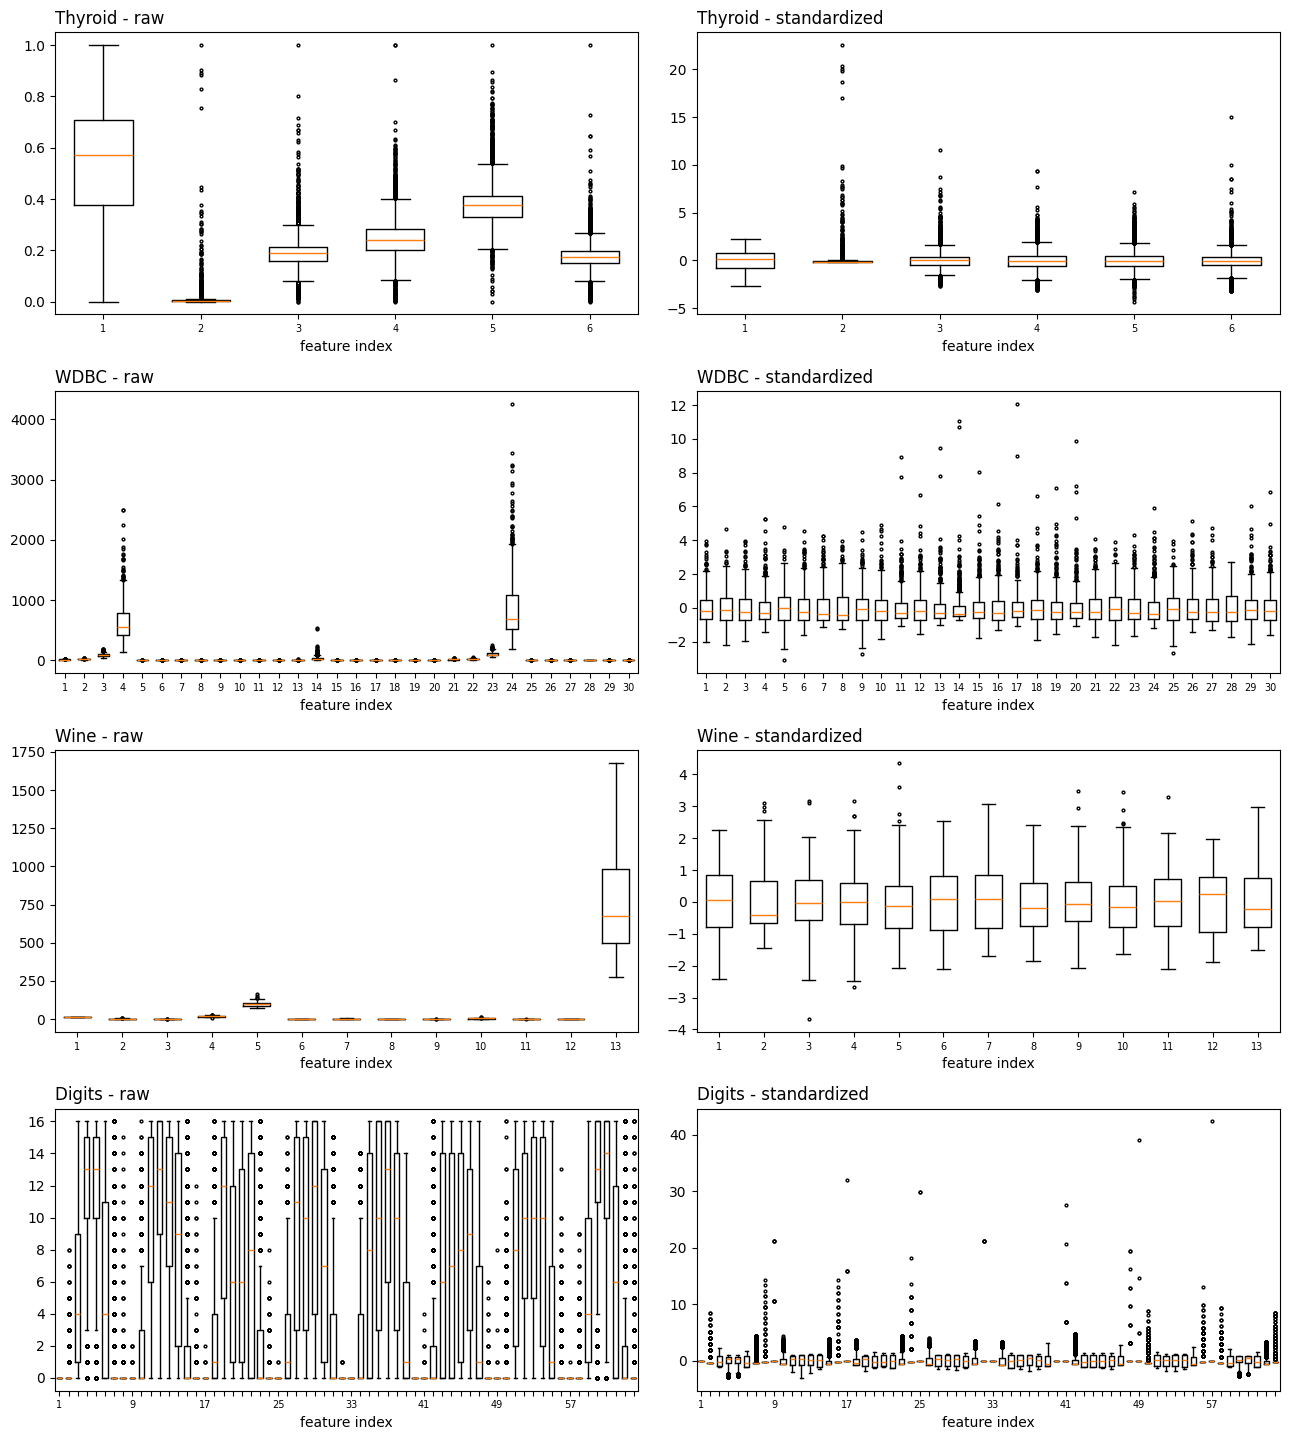

In [16]:
fig, axes = plt.subplots(4, 2, figsize=(13, 14.5))
for row, (name, (X, cols)) in enumerate(datasets.items()):
    sd = X.std(axis=0)
    sd[sd == 0] = 1.0
    Z = (X - X.mean(axis=0)) / sd
    labels = [str(i + 1) if X.shape[1] <= 30 or i % 8 == 0 else "" for i in range(X.shape[1])]
    for col, (M, title) in enumerate([(X, "raw"), (Z, "standardized")]):
        ax = axes[row, col]
        ax.boxplot(M, tick_labels=labels, widths=0.6, flierprops={"markersize": 2})
        ax.set_title(f"{name} - {title}", loc="left")
        ax.set_xlabel("feature index")
        ax.tick_params(axis="x", labelsize=7)
fig.tight_layout()
fig.savefig("3_1_standardization_boxplots.png", dpi=150)

In [17]:
print(f"\nEffect on one-class k-NN (k={k_31}), test AUC:")
for name, X, y in [("Thyroid", X_thy, y_thy), ("WDBC", X_wdbc, y_wdbc)]:
    X_tr, X_va, y_va, X_te, y_te = split_one_class(X, y)
    raw = auc(*roc_curve(y_te, knn_score(X_te, X_tr, k_31)))
    Z_tr, Z_te = standardize(X_tr, X_te)
    std_ = auc(*roc_curve(y_te, knn_score(Z_te, Z_tr, k_31)))
    print(f"  {name:<8} without standardization: {raw:.3f}   with standardization: {std_:.3f}")


Effect on one-class k-NN (k=5), test AUC:
  Thyroid  without standardization: 0.973   with standardization: 0.991
  WDBC     without standardization: 0.964   with standardization: 0.939


In [18]:
print(f"\nEffect on k-NN classification (k={k_31}), Digits test accuracy:")
for seed in range(5):
    X_tr, X_te, y_tr, y_te = train_test_split(X_dig, y_dig, test_size=0.3, stratify=y_dig, random_state=seed)
    acc_raw = np.mean(knn_classify(X_te, X_tr, y_tr, k_31) == y_te)
    Z_tr, Z_te = standardize(X_tr, X_te)
    acc_std = np.mean(knn_classify(Z_te, Z_tr, y_tr, k_31) == y_te)
    print(f"  split {seed}: without standardization: {acc_raw:.4f}   with standardization: {acc_std:.4f}")


Effect on k-NN classification (k=5), Digits test accuracy:
  split 0: without standardization: 0.9796   with standardization: 0.9704
  split 1: without standardization: 0.9833   with standardization: 0.9852
  split 2: without standardization: 0.9796   with standardization: 0.9648
  split 3: without standardization: 0.9870   with standardization: 0.9685
  split 4: without standardization: 0.9852   with standardization: 0.9796


In [19]:
X_train, X_val, y_val, X_test, y_test = split_one_class(X_thy, y_thy)
X_train, X_val, X_test = standardize(X_train, X_val, X_test)

In [20]:
def sorted_distances(points, train, kmax):
    return np.array([np.sort(np.sqrt(((train - p) ** 2).sum(axis=1)))[:kmax] for p in points])

In [21]:
pool_X = np.vstack([X_train, X_val])
pool_y = np.concatenate([np.zeros(len(X_train), dtype=int), y_val])
cv_auc = []
for rep in range(3):
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=rep)
    for tr_idx, va_idx in folds.split(pool_X, pool_y):
        tr = pool_X[tr_idx][pool_y[tr_idx] == 0]
        tr, va = standardize(tr, pool_X[va_idx])
        D = sorted_distances(va, tr, max(k_values))
        cv_auc.append([auc(*roc_curve(pool_y[va_idx], D[:, :k].mean(axis=1))) for k in k_values])
cv_auc = np.array(cv_auc)
mean_auc, std_auc = cv_auc.mean(axis=0), cv_auc.std(axis=0)
se_auc = std_auc / np.sqrt(len(cv_auc))

In [22]:
i_best = int(np.argmax(mean_auc))
K_best_mean = k_values[i_best]
K = min(k for k, m in zip(k_values, mean_auc) if m >= mean_auc[i_best] - se_auc[i_best])

In [23]:
print("\nk selection: 5-fold CV x 3 repeats on train+validation data, metric = AUC")
for k in [2, 3, 5, 7, 10, 15, 20, 30, 40, 50]:
    i = k_values.index(k)
    print(f"  k = {k:>2}   CV AUC = {mean_auc[i]:.4f} +/- {std_auc[i]:.4f}")
print(f"highest mean AUC        : k = {K_best_mean} ({mean_auc[i_best]:.4f})")
print(f"one-standard-error rule : k = {K}  (mean AUC >= {mean_auc[i_best] - se_auc[i_best]:.4f})")
print(f"selected k = {K}")


k selection: 5-fold CV x 3 repeats on train+validation data, metric = AUC
  k =  2   CV AUC = 0.9752 +/- 0.0239
  k =  3   CV AUC = 0.9777 +/- 0.0196
  k =  5   CV AUC = 0.9810 +/- 0.0143
  k =  7   CV AUC = 0.9824 +/- 0.0126
  k = 10   CV AUC = 0.9836 +/- 0.0115
  k = 15   CV AUC = 0.9843 +/- 0.0107
  k = 20   CV AUC = 0.9845 +/- 0.0104
  k = 30   CV AUC = 0.9846 +/- 0.0104
  k = 40   CV AUC = 0.9845 +/- 0.0105
  k = 50   CV AUC = 0.9846 +/- 0.0105
highest mean AUC        : k = 26 (0.9846)
one-standard-error rule : k = 7  (mean AUC >= 0.9820)
selected k = 7


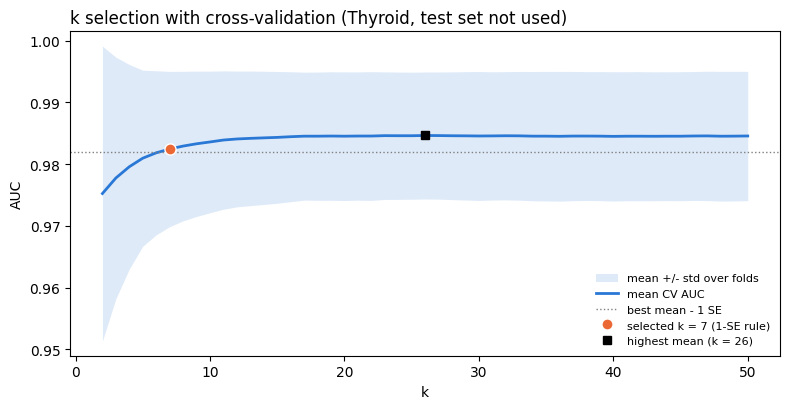

In [24]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.fill_between(k_values, mean_auc - std_auc, mean_auc + std_auc, color=blue, alpha=0.15, lw=0,
                label="mean +/- std over folds")
ax.plot(k_values, mean_auc, color=blue, lw=2, label="mean CV AUC")
ax.axhline(mean_auc[i_best] - se_auc[i_best], color="gray", ls=":", lw=1, label="best mean - 1 SE")
ax.plot(K, mean_auc[k_values.index(K)], "o", color=orange, ms=8, mec="white", label=f"selected k = {K} (1-SE rule)")
ax.plot(K_best_mean, mean_auc[i_best], "s", color="black", ms=6, label=f"highest mean (k = {K_best_mean})")
ax.set_xlabel("k")
ax.set_ylabel("AUC")
ax.set_title("k selection with cross-validation (Thyroid, test set not used)", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("3_2_k_selection.png", dpi=150)

In [25]:
s_val = knn_score(X_val, X_train, K)
s_test = knn_score(X_test, X_train, K)
print(f"val: {np.sum(y_val == 0)} normal + {np.sum(y_val == 1)} anomaly | "
      f"test: {np.sum(y_test == 0)} normal + {np.sum(y_test == 1)} anomaly")

val: 736 normal + 46 anomaly | test: 736 normal + 47 anomaly


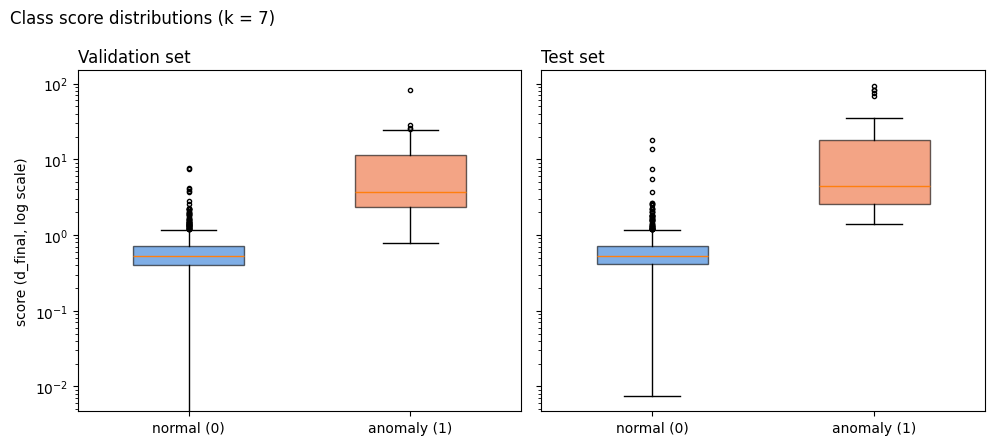

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, (s, yy, title) in zip(axes, [(s_val, y_val, "Validation"), (s_test, y_test, "Test")]):
    bp = ax.boxplot([s[yy == 0], s[yy == 1]], tick_labels=["normal (0)", "anomaly (1)"],
                    widths=0.5, patch_artist=True, flierprops={"markersize": 3})
    for patch, c in zip(bp["boxes"], [blue, orange]):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)
    ax.set_yscale("log")
    ax.set_title(f"{title} set", loc="left")
axes[0].set_ylabel("score (d_final, log scale)")
fig.suptitle(f"Class score distributions (k = {K})", x=0.01, ha="left")
fig.tight_layout()
fig.savefig("3_2_score_boxplot.png", dpi=150)

In [27]:
thresholds = np.unique(s_val)
ba_val = [balanced_accuracy(*confusion(y_val, predict(s_val, t))) for t in thresholds]
f1_val = [f1_score(*confusion(y_val, predict(s_val, t))) for t in thresholds]

In [28]:
th_ba = thresholds[int(np.argmax(ba_val))]
th_f1 = thresholds[int(np.argmax(f1_val))]
print(f"\nBest threshold on validation:")
print(f"  Balanced Accuracy: Th = {th_ba:.3f}  (val BA = {max(ba_val):.3f})")
print(f"  F1-score         : Th = {th_f1:.3f}  (val F1 = {max(f1_val):.3f})")


Best threshold on validation:
  Balanced Accuracy: Th = 1.140  (val BA = 0.939)
  F1-score         : Th = 2.223  (val F1 = 0.791)


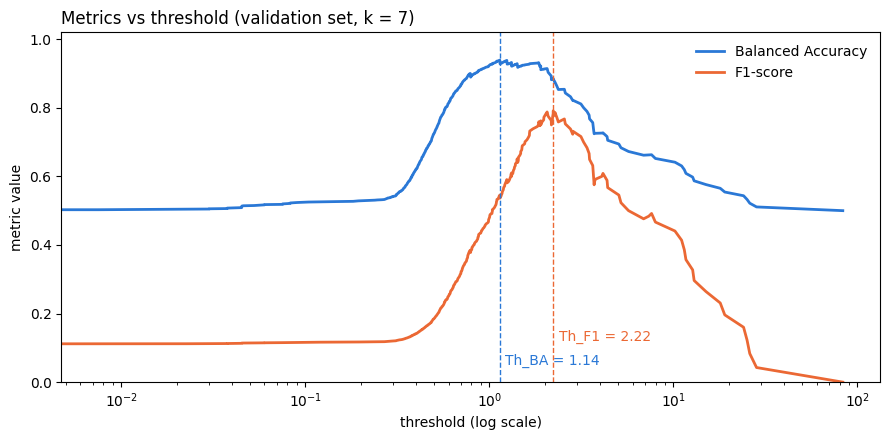

In [29]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thresholds, ba_val, color=blue, lw=2, label="Balanced Accuracy")
ax.plot(thresholds, f1_val, color=orange, lw=2, label="F1-score")
ax.axvline(th_ba, color=blue, ls="--", lw=1)
ax.axvline(th_f1, color=orange, ls="--", lw=1)
ax.annotate(f"Th_BA = {th_ba:.2f}", (th_ba, 0.05), xytext=(4, 0), textcoords="offset points", color=blue)
ax.annotate(f"Th_F1 = {th_f1:.2f}", (th_f1, 0.12), xytext=(4, 0), textcoords="offset points", color=orange)
ax.set_xscale("log")
ax.set_xlabel("threshold (log scale)")
ax.set_ylabel("metric value")
ax.set_ylim(0, 1.02)
ax.set_title(f"Metrics vs threshold (validation set, k = {K})", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("3_2_metrics_vs_threshold.png", dpi=150)

In [30]:
print("\nTest set results:")
for name, th in [("Balanced Accuracy", th_ba), ("F1-score", th_f1)]:
    tn, fp, fn, tp = confusion(y_test, predict(s_test, th))
    print(f"\nThreshold chosen by {name}: Th = {th:.3f}")
    print("               pred normal  pred anomaly")
    print(f"true normal    TN={tn:<9} FP={fp}")
    print(f"true anomaly   FN={fn:<9} TP={tp}")
    print(f"  Balanced Accuracy = {balanced_accuracy(tn, fp, fn, tp):.3f}   "
          f"F1 = {f1_score(tn, fp, fn, tp):.3f}   "
          f"TPR = {tp / (tp + fn):.3f}   TNR = {tn / (tn + fp):.3f}   "
          f"Precision = {tp / (tp + fp) if tp + fp else 0:.3f}")


Test set results:

Threshold chosen by Balanced Accuracy: Th = 1.140
               pred normal  pred anomaly
true normal    TN=670       FP=66
true anomaly   FN=0         TP=47
  Balanced Accuracy = 0.955   F1 = 0.588   TPR = 1.000   TNR = 0.910   Precision = 0.416

Threshold chosen by F1-score: Th = 2.223
               pred normal  pred anomaly
true normal    TN=724       FP=12
true anomaly   FN=9         TP=38
  Balanced Accuracy = 0.896   F1 = 0.784   TPR = 0.809   TNR = 0.984   Precision = 0.760


In [31]:
fpr, tpr = roc_curve(y_test, s_test)
auc_test = auc(fpr, tpr)
print(f"AUC = {auc_test:.4f}")

points = {}
for name, th in [("BA", th_ba), ("F1", th_f1)]:
    tn, fp, fn, tp = confusion(y_test, predict(s_test, th))
    points[name] = (fp / (fp + tn), tp / (tp + fn))

AUC = 0.9909


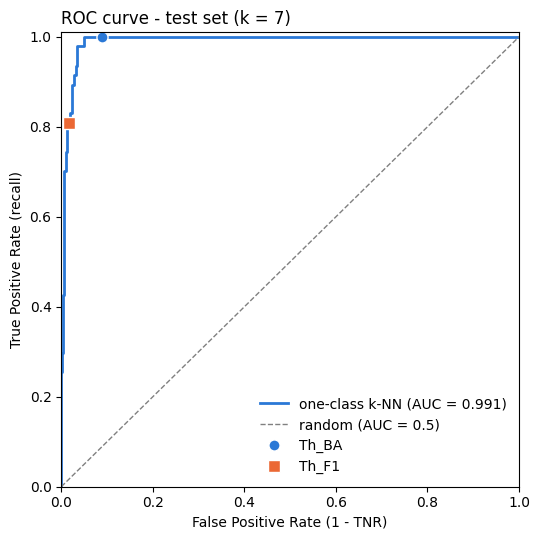

In [32]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(fpr, tpr, color=blue, lw=2, label=f"one-class k-NN (AUC = {auc_test:.3f})")
ax.plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="random (AUC = 0.5)")
ax.plot(*points["BA"], "o", color=blue, ms=8, mec="white", label="Th_BA")
ax.plot(*points["F1"], "s", color=orange, ms=8, mec="white", label="Th_F1")
ax.set_xlabel("False Positive Rate (1 - TNR)")
ax.set_ylabel("True Positive Rate (recall)")
ax.set_title(f"ROC curve - test set (k = {K})", loc="left")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig("3_3_roc_curve.png", dpi=150)

In [33]:
X_tr_raw, _, _, X_te_raw, _ = split_one_class(X_thy, y_thy)    # same split, unstandardized
rng = np.random.default_rng(SEED)
scores = {
    "k-NN, standardized": s_test,
    "k-NN, not standardized": knn_score(X_te_raw, X_tr_raw, K),
    "single feature f3 (|z|)": np.abs(X_test[:, 2]),     # X_test is standardized with train mean/std
    "single feature f1 (|z|)": np.abs(X_test[:, 0]),
    "random score": rng.random(len(y_test)),
}
colors = [blue,orange, "#1baf7a", "#eda100", "gray"]


AUC of different scores (test set):
  k-NN, standardized         AUC = 0.991
  k-NN, not standardized     AUC = 0.973
  single feature f3 (|z|)    AUC = 0.850
  single feature f1 (|z|)    AUC = 0.495
  random score               AUC = 0.477

saved figures: 3_1_standardization_boxplots.png, 3_2_score_boxplot.png, 3_2_k_selection.png, 3_2_metrics_vs_threshold.png, 3_3_roc_curve.png, 3_3_roc_comparison.png


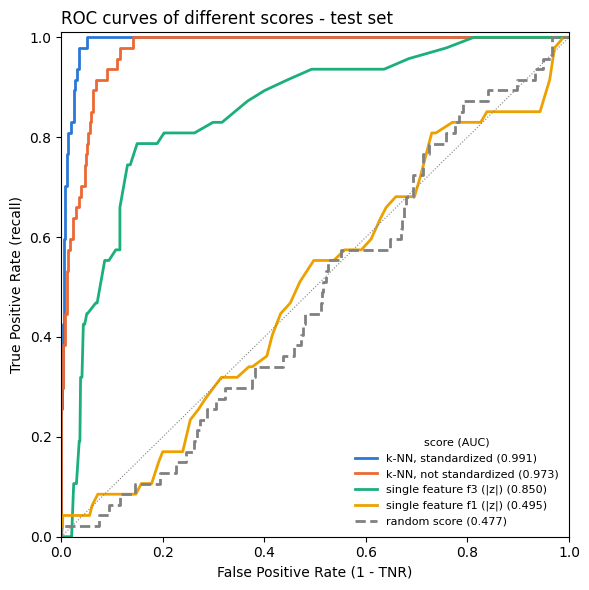

In [34]:
print("\nAUC of different scores (test set):")
fig, ax = plt.subplots(figsize=(6, 6))
for (name, sc), c in zip(scores.items(), colors):
    f, t = roc_curve(y_test, sc)
    a = auc(f, t)
    print(f"  {name:<26} AUC = {a:.3f}")
    ax.plot(f, t, color=c, lw=2, ls="--" if name == "random score" else "-", label=f"{name} ({a:.3f})")
ax.plot([0, 1], [0, 1], color="gray", lw=0.8, ls=":")
ax.set_xlabel("False Positive Rate (1 - TNR)")
ax.set_ylabel("True Positive Rate (recall)")
ax.set_title("ROC curves of different scores - test set", loc="left")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.legend(loc="lower right", frameon=False, fontsize=8, title="score (AUC)", title_fontsize=8)
fig.tight_layout()
fig.savefig("3_3_roc_comparison.png", dpi=150)
print("\nsaved figures: 3_1_standardization_boxplots.png, 3_2_score_boxplot.png, "
      "3_2_k_selection.png, 3_2_metrics_vs_threshold.png, 3_3_roc_curve.png, 3_3_roc_comparison.png")